# Drag Pulse Calibration

In [83]:
from pathlib import Path

import numpy as np

from qblox_lab.config.device import save_device_configuration
from qblox_lab.config.hardware import create_hardware_agent
from qblox_lab.config.sessions import CONFIG_DIR, SESSIONS
from qblox_lab.config.session_paths import save_config_snapshot, save_result_figures
from qblox_lab.experiments.cal17_drag_pulse_calibration import MultiplexedDRAGCalibration

## Run parameters

In [90]:
SESSION = SESSIONS["AS_QRC"]
HARDWARE_CONFIG = SESSION.hardware_config
DEVICE_CONFIG = SESSION.device_config
FLUX_CONFIG = SESSION.flux_config  # If None, leave the existing hardware flux unchanged
OUTPUT_DIR = SESSION.output_dir
EXPERIMENT_NAME = "drag_calibration"

QUBITS = ["q1"]
BETA_START = -0.3e-9
BETA_STOP = 1.3e-9
BETA_POINTS = 101
PULSE_REPETITION = 1
REPETITIONS = 600
RESET_TYPE = "thermal"  # "thermal" or "active" (ConditionalReset)

TIMEOUT = 300
CREATE_DUMMY_CONNECTIONS = False

PLOT_RESULTS = True
SAVE_FITTED_DEVICE = SESSION.device_config

## Hardware and experiment

In [91]:
import atexit

from qcodes.instrument import Instrument

hardware_agent = create_hardware_agent(
    hardware_configuration=HARDWARE_CONFIG,
    device_configuration=DEVICE_CONFIG,
    output_dir=OUTPUT_DIR,
    create_dummy_connections=CREATE_DUMMY_CONNECTIONS,
)

experiment = MultiplexedDRAGCalibration(
    hardware_agent=hardware_agent,
    qubits=QUBITS,
    flux_config=FLUX_CONFIG,
)

atexit.register(Instrument.close_all)

<bound method Instrument.close_all of <class 'qcodes.instrument.instrument.Instrument'>>

## Measurement

In [92]:
dataset = experiment.run_measurement(
    repetitions=REPETITIONS,
    reset_type=RESET_TYPE,
    beta_start=BETA_START,
    beta_stop=BETA_STOP,
    beta_npoints=BETA_POINTS,
    pulse_repetitions=PULSE_REPETITION,
    timeout=TIMEOUT,
)
dataset

<xarray.Dataset> Size: 12kB
Dimensions:            (acq_index_S_21_q1: 303)
Coordinates:
  * acq_index_S_21_q1  (acq_index_S_21_q1) int64 2kB 0 1 2 3 ... 299 300 301 302
    beta_q1            (acq_index_S_21_q1) float64 2kB -3e-10 -3e-10 ... 1.3e-09
    seq_idx_q1         (acq_index_S_21_q1) int64 2kB 0 1 2 0 1 2 ... 0 1 2 0 1 2
Data variables:
    S_21_q1            (acq_index_S_21_q1) complex128 5kB (-0.000286093147993...
Attributes:
    tuid:     20261016-070503-974-3eda06

## Optional: Simulated data

In [87]:
# dataset = experiment.simulated_data(
#     delays=DELAYS,
#     repetitions=REPETITIONS,
#     t1=100e-6,
#     noise=0.002,
#     seed=42,
# )

## Analysis

In [93]:
results = experiment.analysis()
for qubit, result in results.items():
    if result['success']:
        print(f"{qubit}: optimal beta = {result['optimal_beta']/1e-9:.3f}")
    else:
        print(f"{qubit}: DRAG fit failed")

  -> Optimal Beta found: -0.0789e-9
q1: optimal beta = -0.079


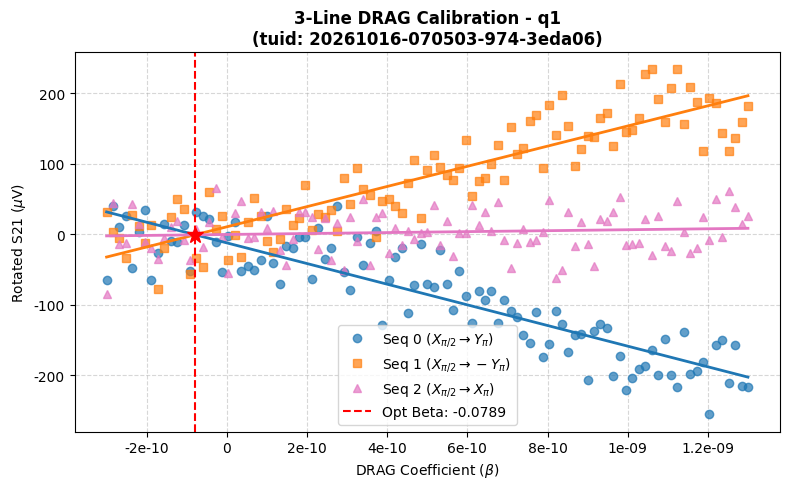

In [94]:
if PLOT_RESULTS:
    experiment.plot_analysis()

In [95]:
if SAVE_FITTED_DEVICE is not None:
    experiment.update_device()
    saved_path = save_device_configuration(
        hardware_agent.quantum_device,
        SAVE_FITTED_DEVICE,
    )
    print(f"Updated device configuration saved to {saved_path}")

Updated device configuration saved to /home/boris0403/qblox-measurement-nodes/config/10Q9C/dut_config_AS_QRC.json


In [96]:
if PLOT_RESULTS and experiment.figures:
    save_result_figures(SESSION, dataset, EXPERIMENT_NAME, experiment.figures)
save_config_snapshot(SESSION, dataset, EXPERIMENT_NAME)


## Release hardware connection

In [ ]:
from qcodes.instrument import Instrument

Instrument.close_all()